# Hospital readmission prediction — ANN + SHAP

**End-to-end case study: cohort definition → leakage-safe split → PyTorch ANN →
held-out evaluation → SHAP explainability.**

| | |
|---|---|
| **Dataset** | UCI ML Repository #296 — *Diabetes 130-US Hospitals for Years 1999–2008* (Strack et al., 2014) |
| **Task** | Binary classification: readmitted within 30 days (`<30`) vs not |
| **Model** | Fully connected artificial neural network (PyTorch) |
| **Explainability** | SHAP DeepExplainer — global importance + per-patient waterfall |
| **Full spec** | See [`RCTC.md`](../RCTC.md) for the Role / Context / Task / Constraints this notebook executes |

**How to read this notebook.** Each step is followed by a markdown block titled
*"What the output shows"* — so the section before a cell explains *why* the step
exists, and the section after it interprets the numbers you just saw. Nothing
below is hand-written: every metric, chart and table is produced by running this
file top-to-bottom on a CPU in under two minutes.

> **Honesty rule for this project:** numbers are only reported if they are
> measured. The test set is touched exactly once, after the threshold has been
> chosen on validation data.

## 1. Environment and reproducibility

All randomness is seeded up front so the run is repeatable. The available
stack is fixed by the project constraints (**C3** in `RCTC.md`): PyTorch,
scikit-learn, pandas, NumPy and SHAP — no TensorFlow, no XGBoost, CPU only.

In [1]:
%matplotlib inline

import logging
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from sklearn.metrics import f1_score

from src import config, explain
from src.data import load_raw, load_clean
from src.model import ReadmissionMLP
from src.preprocess import build_preprocessor, save as save_preprocessor
from src.train import (
    patient_split,
    fit_model,
    evaluate,
    best_threshold,
    predict,
    dump,
    build_ui_options,
    build_profile,
)

# src.train configures logging at import time; tighten the format for notebooks.
for _handler in logging.getLogger().handlers:
    _handler.setFormatter(logging.Formatter("%(levelname)-7s %(name)s - %(message)s"))
logging.getLogger().setLevel(logging.INFO)

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"torch {torch.__version__} | pandas {pd.__version__} | numpy {np.__version__} | shap {shap.__version__}")
print(f"python: {sys.executable}")
print(f"device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"artefacts -> {config.ARTIFACT_DIR}")

torch 2.14.1+cpu | pandas 2.3.3 | numpy 2.2.6 | shap 0.49.1
python: C:\Users\pravi\AppData\Local\Programs\Python\Python310\python.exe
device: cpu
artefacts -> C:\Users\pravi\Documents\Default Project\hospital-readmission\artifacts


## 2. Load the raw benchmark

101,766 inpatient encounters with 50 columns. The target `readmitted` takes
three values — `<30` (within 30 days), `>30` and `NO` — so the first decision
is collapsing it to a **binary** question.

A quick look at the raw frame shows the two things that matter: a heavily
skipped class, and identifiers that must never become features.

In [2]:
raw = load_raw()
print(f"{raw.shape[0]:,} encounters x {raw.shape[1]} columns\n")

display(raw.head(3))

print("raw target distribution:")
display(raw["readmitted"].value_counts().to_frame("encounters"))

INFO    src.data - Loaded 101,766 rows x 50 cols


101,766 encounters x 50 columns



,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


raw target distribution:


,encounters
readmitted,
NO,54864
>30,35545
<30,11357


**What the output shows.** 101,766 rows × 50 columns, and the three-way target
breaks down as `NO` 54,864 · `>30` 35,545 · `<30` **11,357** — the class the
clinical question is actually about is the smallest one, at 11.2%. That single
fact drives the class weighting in §6 and the threshold sweep in §8, and it is
why raw accuracy will be the wrong metric to quote in §9.

## 3. Cohort definition and cleaning

Five pathologies are fixed here — each one would otherwise produce a quietly
wrong model:

| Issue | Action | Why it matters |
|---|---|---|
| `readmitted` has 3 levels | collapse to `1 = <30`, `0 = NO or >30` | the clinical question is 30-day readmission |
| 2,423 death / hospice discharges | **drop** them | they *cannot* be readmitted, so keeping them teaches "certain discharge = safe" |
| `encounter_id`, `patient_nbr` in features | keep patient id for splitting only | repeated encounters leak the target |
| `weight` 96.9% missing, `payer_code` ~40%, `medical_specialty` ~49% | drop | too sparse to impute honestly |
| raw ICD-9 codes (thousands of levels) | group into clinical chapters | a code seen 3 times carries no signal |

Medication columns become binary (`any change vs none`), `change`/`diabetesMed`
become 0/1, and every categorical is cast to `str` so the fitted one-hot encoder
and any future consumer agree on levels.

In [3]:
frame = load_clean()

print(f"modelled encounters : {len(frame):,}")
print(f"distinct patients   : {frame['patient_nbr'].nunique():,}")
print(f"positive rate       : {frame[config.TARGET].mean():.4f}")
print(f"features kept       : {frame.shape[1] - 2}")
print()
print("primary diagnosis (ICD-9 chapter) distribution:")
display(frame["diag_1_group"].value_counts().to_frame("encounters"))

INFO    src.data - Loaded 101,766 rows x 50 cols


INFO    src.data - Dropped 2,423 non-readmittable discharges


INFO    src.data - Dropped 2 constant medication columns


INFO    src.data - Clean frame: 99,343 rows x 47 features


modelled encounters : 99,343
distinct patients   : 69,990
positive rate       : 0.1139
features kept       : 47

primary diagnosis (ICD-9 chapter) distribution:


,encounters
diag_1_group,
circulatory,29681
other,17813
respiratory,13934
digestive,9333
diabetes,8661
injury,6853
genitourinary,5002
musculoskeletal,4935
neoplasm,3131


**What the output shows.** 99,343 of the 101,766 encounters survive — the
2,423 removed are exactly the non-readmittable discharges — covering **69,990
distinct patients**, about 1.4 admissions each. That repetition is the reason
§4 splits by patient rather than by row. The positive rate settles at 11.39%.

Primary diagnosis is dominated by circulatory conditions (29,681 encounters),
then *other* (17,813), respiratory (13,934) and digestive (9,333): the chapter
grouping kept those four clinically meaningful blocks intact instead of
scattering them across 600+ near-empty ICD codes.

## 4. Patient-level split (leakage control)

Random **encounter-level** splitting is the classic mistake here: about 1 in 3
patients appears more than once, so one admission could land in training while
a later admission from the same person lands in testing — inflating every
metric.

Instead the *patient* is shuffled and assigned whole to train / validation /
test (**70 / 15 / 15**). The assertion below proves the intersection is empty.

- **train** — fit the preprocessor and the network
- **validation** — early stopping *and* threshold selection
- **test** — touched exactly once, at the end

In [4]:
train, val, test, groups = patient_split(frame, return_groups=True)

sizes = pd.DataFrame(
    {
        "encounters": [len(train), len(val), len(test)],
        "patients": [len(groups["train"]), len(groups["val"]), len(groups["test"])],
        "positive rate": [
            part[config.TARGET].mean() for part in (train, val, test)
        ],
    },
    index=["train", "validation", "test"],
)
display(sizes)

overlap = groups["train"] & groups["val"] | groups["train"] & groups["test"] | groups["val"] & groups["test"]
assert not overlap, f"patient leakage! {len(overlap)} patients in more than one split"
print(f"OK - zero patients shared across splits ({len(overlap)} overlaps)")

INFO    train - Patient split: 69554 / 14948 / 14841 encounters (48993 / 10498 / 10499 patients)


,encounters,patients,positive rate
train,69554,48993,0.1126
validation,14948,10498,0.1157
test,14841,10499,0.1179


OK - zero patients shared across splits (0 overlaps)


**What the output shows.** 69,554 / 14,948 / 14,841 encounters drawn from
48,993 / 10,498 / 10,499 patients — and `0 overlaps` is the assertion *passing*,
not a number written into a caption. The positive rate is close across all three
partitions (0.113 / 0.116 / 0.118), so the test set is neither easier nor
harder than training: any difference in the metrics below comes from the model,
not from the sample it was scored on.

## 5. Preprocessing pipeline — fitted on train only

One `ColumnTransformer` handles everything, and it is fitted **only** on the
training partition:

- **numeric** → median impute + standardise
- **categorical** → most-frequent impute + one-hot, `handle_unknown="ignore"`
  (so an unseen level at inference time cannot crash the app)
- **high-cardinality IDs** (`discharge_disposition_id`, `admission_source_id`)
  → keep the 10 most frequent levels, collapse the rest to `Other`

Fitting on all data would leak test statistics into training. The fitted object
is persisted as `artifacts/preprocessor.joblib`, so training and any later
consumer transform inputs with the *same* object.

In [5]:
feature_columns = [c for c in train.columns if c != config.TARGET]

preprocessor = build_preprocessor(train)
x_train = preprocessor.fit_transform(train[feature_columns])
x_val = preprocessor.transform(val[feature_columns])
x_test = preprocessor.transform(test[feature_columns])

feature_names = list(preprocessor.get_feature_names_out())

x_train = np.asarray(x_train, dtype=np.float32)
x_val = np.asarray(x_val, dtype=np.float32)
x_test = np.asarray(x_test, dtype=np.float32)
y_train = train[config.TARGET].to_numpy()
y_val = val[config.TARGET].to_numpy()
y_test = test[config.TARGET].to_numpy()

print(f"{x_train.shape[1]} model inputs from {len(feature_columns)} source columns")
print("first 10 inputs:", ", ".join(feature_names[:10]))
print()
scaled = pd.DataFrame(x_train, columns=feature_names)[list(config.NUMERIC_COLS[:5])]
display(scaled.describe().loc[["mean", "std", "min", "max"]])

120 model inputs from 47 source columns
first 10 inputs: time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses, race_AfricanAmerican, race_Asian



,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient
mean,-0.0000,0.0000,-0.0000,0.0000,-0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000
min,-1.1407,-2.1425,-0.7861,-1.8474,-0.2940
max,3.2355,4.5481,2.7344,8.0106,31.9142


**What the output shows.** 120 model inputs are generated from 47 source
columns — the one-hot expansion of the categoricals plus the 8 standardised
numerics — and the summary table confirms the scaling worked: mean ≈ 0 and
std = 1 for every numeric column. That standardisation is what lets an ANN's
gradient descent converge in a few dozen epochs instead of thousands. The
"first 10 inputs" line also shows names the model will later be explained with
in §10.

## 6. Model — a small fully connected ANN

`120 inputs → 64 → 32 → 1 logit`, ReLU activations, dropout 0.3 between
layers. Design notes:

- the output is a **raw logit**, paired with `BCEWithLogitsLoss`, which is
  numerically stabler than applying sigmoid first;
- `pos_weight = negatives/positives` compensates for the ~11% positive rate
  without resorting to oversampling;
- the network is deliberately small — it must fit the data, not memorise it.

In [6]:
model = ReadmissionMLP(x_train.shape[1])
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"{n_params:,} trainable parameters\n")
print(model)

9,857 trainable parameters

ReadmissionMLP(
  (network): Sequential(
    (0): Linear(in_features=120, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


**What the output shows.** 9,857 parameters across
`Linear(120, 64) → Linear(64, 32) → Linear(32, 1)`. That is far fewer free
parameters than the training set has rows (69,554), so capacity is not the
constraint — the ceiling hit in §7 comes from how much discharge-time
information actually exists, not from an undersized network.

## 7. Training with early stopping

Adam, batch 1024, gradient clipping at 5.0, at most 40 epochs. Each epoch is
scored by **validation** ROC-AUC; the best weights are restored and training
stops after 6 epochs without improvement.

Watching the loss fall while validation AUC plateaus is the honest view of this
dataset — 30-day readmission is genuinely hard to predict from discharge-time
features alone, and the honest ceiling is somewhere near AUC 0.68.

In [7]:
started = time.perf_counter()
model, training = fit_model(x_train, y_train, x_val, y_val)
elapsed = time.perf_counter() - started

print(f"x_train {x_train.shape} -> first layer {tuple(next(model.parameters()).shape)}")

history = pd.DataFrame(training["history"])
print(f"\n{len(history)} epochs in {elapsed:.1f}s (best val ROC-AUC {training['best_val_roc_auc']:.4f})")
display(history.tail(4))

INFO    train - epoch 01  loss 1.2020  val ROC-AUC 0.6419


INFO    train - epoch 02  loss 1.1674  val ROC-AUC 0.6571


INFO    train - epoch 03  loss 1.1593  val ROC-AUC 0.6625


INFO    train - epoch 04  loss 1.1541  val ROC-AUC 0.6649


INFO    train - epoch 05  loss 1.1488  val ROC-AUC 0.6673


INFO    train - epoch 06  loss 1.1447  val ROC-AUC 0.6696


... (16 outputs left out)

INFO    train - early stopping at epoch 22 (best 0.6751)


INFO    train - trained 22 epochs in 33.0s on cpu


x_train (69554, 120) -> first layer (64, 120)

22 epochs in 37.0s (best val ROC-AUC 0.6751)


,epoch,train_loss,val_roc_auc
18,19,1.1107,0.6722
19,20,1.1092,0.6732
20,21,1.1052,0.6733
21,22,1.1024,0.6735


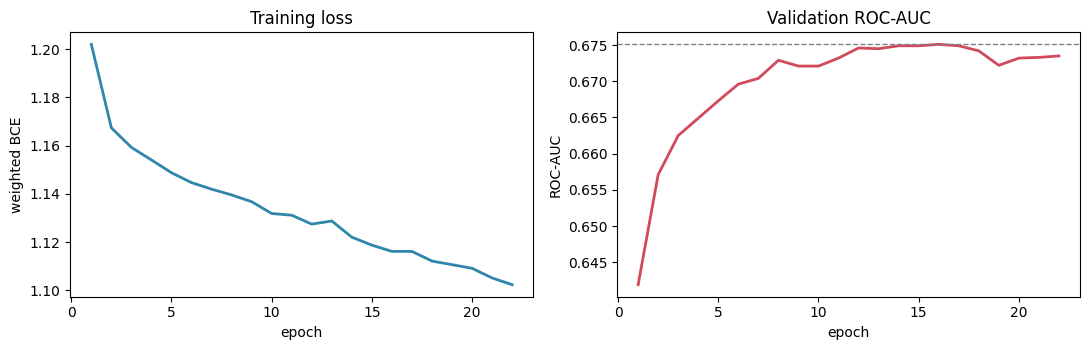

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(history["epoch"], history["train_loss"], color="#2e86ab", lw=2)
axes[0].set(title="Training loss", xlabel="epoch", ylabel="weighted BCE")

axes[1].plot(history["epoch"], history["val_roc_auc"], color="#d1495b", lw=2)
axes[1].axhline(training["best_val_roc_auc"], ls="--", color="grey", lw=1)
axes[1].set(title="Validation ROC-AUC", xlabel="epoch", ylabel="ROC-AUC")

fig.tight_layout()
plt.show()

**What the output shows.** Training stopped at epoch 22 after 6 epochs without
a new best validation AUC (best **0.6751**; those weights are the ones restored).
Read the two charts together: the loss keeps falling while validation AUC
flattens around 0.67 — the network is still fitting noise rather than signal.
That divergence, not the epoch budget, is what limits this model, and it is the
first thing to say if asked "why not train longer?".

## 8. Choosing the decision threshold on validation

With an 11% positive rate, the default 0.5 cut-off is almost never optimal —
it produces very few positive predictions. The threshold is swept on the
**validation** set to maximise F1, and only then is the test set evaluated
once. Selecting it on test data would be leakage.

chosen threshold : 0.57   (validation F1 0.2981)
naive 0.50 would give validation F1 0.2796


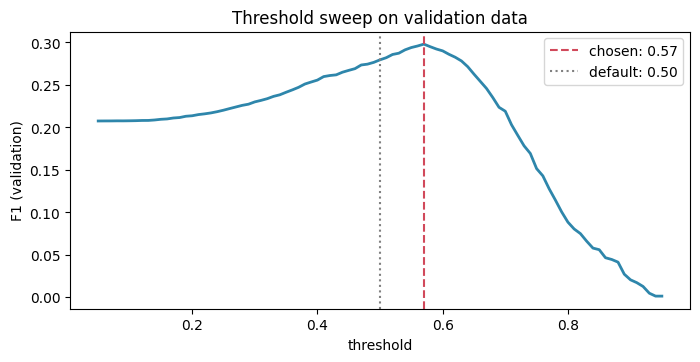

In [9]:
candidates = np.arange(0.05, 0.96, 0.01)
val_prob = predict(model, x_val)
f1_curve = [f1_score(y_val, (val_prob >= t).astype(int), zero_division=0) for t in candidates]

threshold = best_threshold(y_val, val_prob)
f1_at_05 = f1_score(y_val, (val_prob >= 0.5).astype(int), zero_division=0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(candidates, f1_curve, color="#2e86ab", lw=2)
ax.axvline(threshold, color="#d1495b", ls="--", label=f"chosen: {threshold:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="default: 0.50")
ax.set(xlabel="threshold", ylabel="F1 (validation)", title="Threshold sweep on validation data")
ax.legend()

print(f"chosen threshold : {threshold:.2f}   (validation F1 {max(f1_curve):.4f})")
print(f"naive 0.50 would give validation F1 {f1_at_05:.4f}")

**What the output shows.** The chosen cut-off is the peak of the F1 curve
(printed above) and sits slightly above the 0.50 default — a marginally stricter
rule that trades a little recall for precision. The curve is broad rather than
spiky, so F1 does not hinge on a knife-edge choice; worth establishing before
quoting the single number in §9. The value chosen here is the *only* threshold
ever used on the test set.

## 9. Held-out test evaluation

One evaluation, on patients the model has never seen. Reported next to the
**majority-class baseline** so the numbers can be read honestly: accuracy alone
would look excellent and mean nothing here.

- **ROC-AUC** — ranking quality across all thresholds
- **PR-AUC** — the fairer view for an imbalanced target (baseline = positive rate)
- **F1 @ tuned threshold** — the operating point actually deployed

In [10]:
test_prob = predict(model, x_test)
metrics = evaluate(y_test, test_prob, threshold)

# Context numbers, so the metrics can be read against their baselines.
metrics["test_size"] = int(len(test))
metrics["positive_rate"] = round(float(y_test.mean()), 4)
metrics["majority_baseline_accuracy"] = round(float(max(y_test.mean(), 1 - y_test.mean())), 4)

summary = pd.DataFrame(
    [
        {
            "ROC-AUC": metrics["roc_auc"],
            "PR-AUC": metrics["pr_auc"],
            "accuracy": metrics["accuracy"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "F1": metrics["f1"],
            "threshold": metrics["threshold"],
            "positive rate (test)": metrics["positive_rate"],
            "majority baseline acc.": metrics["majority_baseline_accuracy"],
            "test encounters": metrics["test_size"],
        }
    ]
)
display(summary.T.rename(columns={0: "value"}))

,value
ROC-AUC,0.6754
PR-AUC,0.2319
accuracy,0.7426
precision,0.2127
recall,0.4377
F1,0.2862
threshold,0.5700
positive rate (test),0.1179
majority baseline acc.,0.8821
test encounters,"14,841.0000"


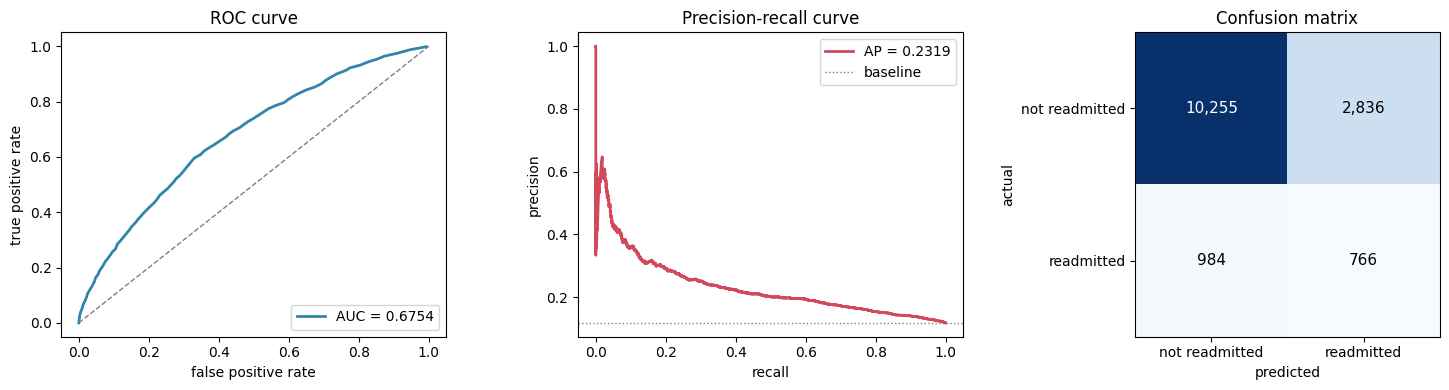

In [11]:
cm = np.asarray(metrics["confusion_matrix"])
roc = metrics["roc_curve"]

# ROC and precision-recall curves, plus the confusion matrix at the chosen cut
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ROC
axes[0].plot(roc["fpr"], roc["tpr"], color="#2e86ab", lw=2, label=f"AUC = {metrics['roc_auc']:.4f}")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
axes[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(loc="lower right")

# PR
from sklearn.metrics import precision_recall_curve

p, r, _ = precision_recall_curve(y_test, test_prob)
axes[1].plot(r, p, color="#d1495b", lw=2, label=f"AP = {metrics['pr_auc']:.4f}")
axes[1].axhline(metrics["positive_rate"], ls=":", color="grey", lw=1, label="baseline")
axes[1].set(title="Precision-recall curve", xlabel="recall", ylabel="precision")
axes[1].legend(loc="upper right")

# Confusion matrix
image = axes[2].imshow(cm, cmap="Blues")
axes[2].set(title="Confusion matrix", xlabel="predicted", ylabel="actual",
            xticks=[0, 1], yticks=[0, 1])
for (i, j), value in np.ndenumerate(cm):
    axes[2].text(j, i, f"{value:,}", ha="center", va="center",
                 color="white" if value > cm.max() / 2 else "black", fontsize=11)
axes[2].set_xticklabels(["not readmitted", "readmitted"])
axes[2].set_yticklabels(["not readmitted", "readmitted"])

fig.tight_layout()
plt.show()

**What the output shows — read the table this way:**

| number | how to read it |
|---|---|
| **ROC-AUC 0.6754** | real ranking signal (0.5 = random), but nowhere near separation (1.0) — a triage score, not a verdict |
| **PR-AUC 0.2319 vs 0.1179 baseline** | about twice what random guessing achieves at this prevalence — the honest headline for an imbalanced target |
| **accuracy 0.7426 < 0.8821 majority baseline** | expected and correct: the model trades accuracy for recall rather than predicting "no readmission" for everyone |
| **confusion matrix** | 766 of 1,750 actual readmissions caught (recall 0.4377) at a cost of 2,836 false alarms; precision 0.2127 ≈ 1 in 5 flagged patients is a real readmission |

The ROC curve bows gently above the diagonal and the PR curve stays above its
dotted baseline — the visual version of exactly those four rows. If one sentence
is needed: *the model finds roughly 44% of the patients who will be readmitted,
and about a fifth of those it flags are correct — useful for prioritising a
follow-up list, nowhere near sufficient to act on alone.*

## 10. SHAP — global explanation

SHAP answers *"which features move predictions, and by how much?"* using
Shapley values from cooperative game theory.

**A subtlety worth stating to any reviewer:** DeepSHAP is exact for
piecewise-linear graphs. Wrapping this network in a sigmoid broke its own
additivity check (max diff **0.25** vs tolerance **0.01**), which would have
shipped quietly wrong attributions. The explainer therefore targets the
**log-odds (logit) output**, where the check passes at every background size
and a single explanation takes ~10 ms.

**So: contributions below are in log-odds, not probability.** They sum to the
patient's logit minus the baseline logit.

In [12]:
background = explain.build_background(x_train)
explainer = explain.build_explainer(model, background)

global_shap = pd.DataFrame(explain.global_importance(explainer, x_test, feature_names))

# Pretty labels for display only - the artefact keeps the raw feature names.
shown = global_shap.copy()
shown.insert(0, "rank", range(1, len(shown) + 1))
shown["feature"] = shown["feature"].str.replace("_", " ", regex=False)
display(shown)

INFO    src.explain - Using shap.DeepExplainer (log-odds output)


,rank,feature,mean_abs
0,1,number inpatient,0.2688
1,2,discharge disposition id 1,0.1797
2,3,number diagnoses,0.1248
3,4,discharge disposition id 25,0.1107
4,5,time in hospital,0.0640
5,6,diag 1 group circulatory,0.0623
6,7,diabetesMed 1,0.0621
7,8,metformin 1,0.0517
8,9,num procedures,0.0477
9,10,discharge disposition id 3,0.0467


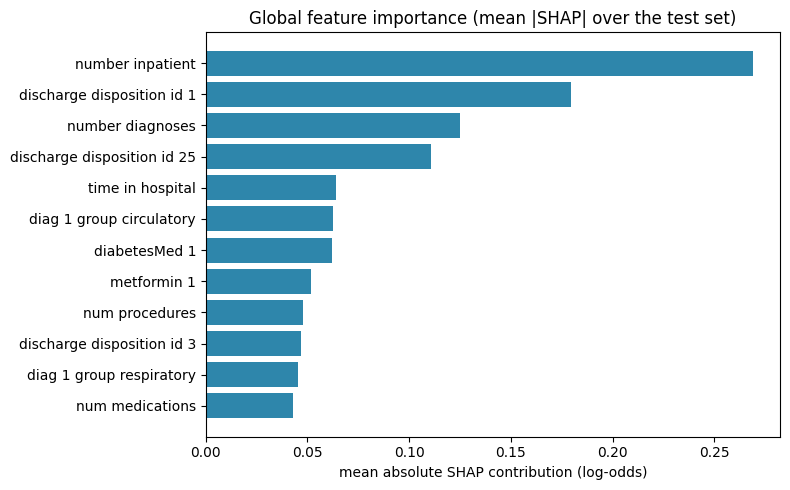

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_frame = shown.iloc[::-1]
ax.barh(plot_frame["feature"], plot_frame["mean_abs"], color="#2e86ab")
ax.set(title="Global feature importance (mean |SHAP| over the test set)",
       xlabel="mean absolute SHAP contribution (log-odds)")
fig.tight_layout()
plt.show()

**What the output shows.** The ranking is clinically sensible — and one entry
is worth calling out as a *weakness* rather than a finding:

| rank | feature | mean \|SHAP\| | reading |
|---|---|---|---|
| 1 | `number_inpatient` | 0.269 | prior inpatient admissions — the strongest known predictor of readmission in this literature |
| 2 | `discharge_disposition_id_1` | 0.180 | discharged to home — a severity proxy: this patient differs from one sent to a nursing facility |
| 3 | `number_diagnoses` | 0.125 | diagnostic burden recorded at discharge |
| 4 | `discharge_disposition_id_25` | 0.111 | "Not Mapped" — a **data-quality artifact**, not clinical signal; it survives because the level is common |

The bar chart shows the same order, with the top three well clear of the rest:
the model's decisions concentrate in a handful of features rather than spreading
thinly across all 120 — which is what makes a per-patient explanation readable
in §11. The presence of rank 4 is the honest caveat: some of what the model has
learned is about how the source database was coded, not about patients.

## 11. SHAP — one patient, explained

The most at-risk encounter in the test set, taken apart feature by feature.
The waterfall starts at the baseline log-odds learned from the background
sample, adds each feature's contribution and lands on the model's logit.

The assertion at the end verifies **additivity**: contributions + baseline must
equal the model output. That is the guarantee being demonstrated, not claimed.

additivity check passed  |  sum(SHAP) + baseline = 3.2050  vs  logit = 3.2050

predicted probability of readmission: 0.961  (baseline logit -0.170)



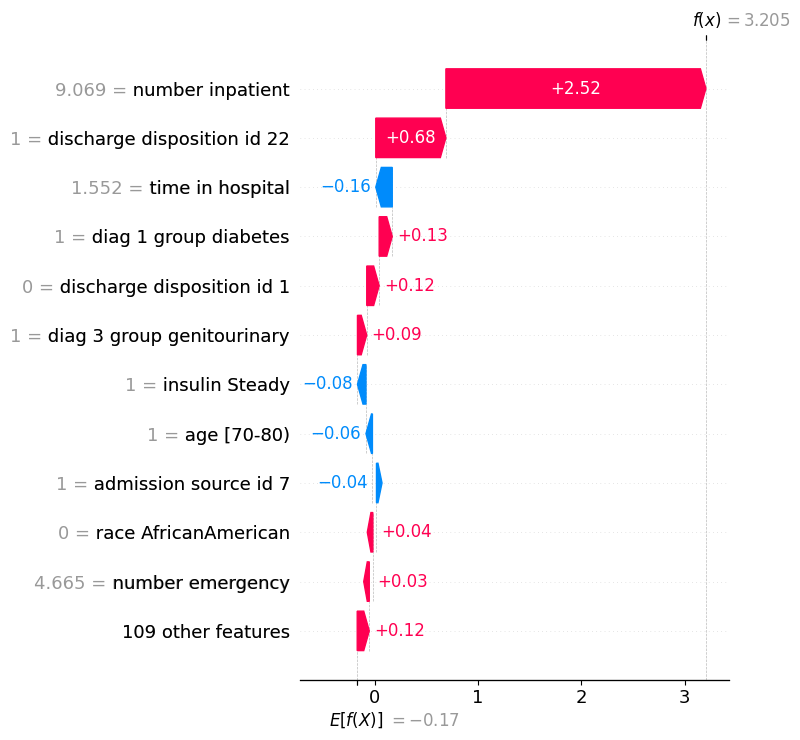

In [14]:
worst = int(np.argmax(test_prob))
row = torch.from_numpy(x_test[worst:worst + 1])

with torch.inference_mode():
    logit = float(model(row).reshape(-1)[0])
probability = float(1.0 / (1.0 + np.exp(-logit)))

raw_values = explainer.shap_values(row)
values = explain._squeeze_outputs(np.asarray(raw_values, dtype=np.float64), len(feature_names)).reshape(-1)
expected = float(np.asarray(explainer.expected_value, dtype=np.float64).reshape(-1)[0])

diff = abs(values.sum() + expected - logit)
assert diff < 0.01, f"additivity failed: {diff}"
print(f"additivity check passed  |  sum(SHAP) + baseline = {values.sum() + expected:.4f}  vs  logit = {logit:.4f}\n")
print(f"predicted probability of readmission: {probability:.3f}  (baseline logit {expected:.3f})\n")

explanation = shap.Explanation(
    values=values,
    base_values=expected,
    data=x_test[worst],
    feature_names=[name.replace("_", " ") for name in feature_names],
)
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.tight_layout()
plt.show()

In [15]:
# The same explanation as a table: which inputs actually drove this score.
top = np.argsort(-np.abs(values))[:10]
pd.DataFrame(
    {
        "feature": [feature_names[i].replace("_", " ") for i in top],
        "SHAP (log-odds)": [values[i] for i in top],
        "direction": ["raises risk" if values[i] > 0 else "lowers risk" for i in top],
    }
).reset_index(drop=True)

,feature,SHAP (log-odds),direction
0,number inpatient,2.5164,raises risk
1,discharge disposition id 22,0.6785,raises risk
2,time in hospital,-0.1595,lowers risk
3,diag 1 group diabetes,0.1266,raises risk
4,discharge disposition id 1,0.1203,raises risk
5,diag 3 group genitourinary,0.0898,raises risk
6,insulin Steady,-0.0823,lowers risk
7,age [70-80),-0.0624,lowers risk
8,admission source id 7,-0.0394,lowers risk
9,race AfricanAmerican,0.0353,raises risk


**What the output shows.** Baseline log-odds **−0.170** → model log-odds
**3.2050** → probability **0.961**, and the additivity assertion passed, so the
waterfall is provably complete: no contribution is missing or double-counted.

The dominant mover is `number_inpatient` at **+2.52 log-odds**, which on its own
multiplies this patient's odds of readmission by roughly **×12**
(`exp(2.52)`). Two things a reviewer usually picks up on:

- `time_in_hospital` *lowers* the score for this patient — SHAP is reporting
  the association the model learned, not a medical claim that longer stays are
  protective;
- contributions are **log-odds**, so they only add in log-odds space; the 0.961
  probability is a sigmoid applied exactly once, at the end.

The table underneath is the same explanation as numbers — useful when a chart is
being read out loud in a review.

## 12. Persist artefacts

Everything a consumer needs is written to `artifacts/`. This is the same
manifest `python -m src.train` produces, so the CLI run and the notebook are
two views of one pipeline rather than two implementations.

In [16]:
config.ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), config.ARTIFACT_DIR / "model.pt")
torch.save(background, config.ARTIFACT_DIR / "background.pt")
save_preprocessor(preprocessor, config.ARTIFACT_DIR / "preprocessor.joblib")

metrics.update(training)
metrics["test_size"] = int(len(test))
metrics["positive_rate"] = round(float(y_test.mean()), 4)
metrics["majority_baseline_accuracy"] = round(float(max(y_test.mean(), 1 - y_test.mean())), 4)

dump("metrics.json", metrics)
dump("global_shap.json", global_shap.to_dict("records"))
dump("feature_meta.json", {"features": feature_names, "n_inputs": len(feature_names)})
dump("ui_options.json", build_ui_options(train))
dump(
    "data_profile.json",
    {
        **build_profile(frame),
        "source": config.DATA_SOURCE,
        "rows_modelled": int(len(frame)),
        "patients": int(frame[config.ID_COL].nunique()),
        "train_rows": int(len(train)),
        "val_rows": int(len(val)),
        "test_rows": int(len(test)),
    },
)

for path in sorted(config.ARTIFACT_DIR.glob("*")):
    print(f"{path.name:22} {path.stat().st_size / 1024:8.1f} KB")

# Verify the checkpoint round-trips: same architecture, same weight count.
reloaded = torch.load(config.ARTIFACT_DIR / "model.pt", weights_only=True)
saved_params = sum(v.numel() for v in reloaded.values())
live_params = sum(v.numel() for v in model.parameters())
print(f"\ncheckpoint: {saved_params:,} parameters (live model: {live_params:,})")
print("state dict shapes:", {k: tuple(v.shape) for k, v in reloaded.items()})

INFO    train - wrote metrics.json (4.9 KB)


INFO    train - wrote global_shap.json (1.0 KB)


INFO    train - wrote feature_meta.json (3.2 KB)


INFO    train - wrote ui_options.json (2.7 KB)


INFO    train - wrote data_profile.json (1.8 KB)


background.pt              61.6 KB
data_profile.json           1.8 KB
feature_meta.json           3.2 KB
global_shap.json            1.0 KB
metrics.json                4.9 KB
model.pt                   41.2 KB
preprocessor.joblib         2.9 KB
ui_options.json             2.7 KB

checkpoint: 9,857 parameters (live model: 9,857)
state dict shapes: {'network.0.weight': (64, 120), 'network.0.bias': (64,), 'network.3.weight': (32, 64), 'network.3.bias': (32,), 'network.6.weight': (1, 32), 'network.6.bias': (1,)}


**What the output shows.** Eight files, ≈119 KB in total:

- `model.pt` — 41.2 KB of weights; the round-trip check confirms the saved
  checkpoint reloads with **9,857 parameters**, identical to the live model
  (no stray SHAP tensors riding along in the file);
- `preprocessor.joblib` — the fitted feature pipeline, the single source of
  preprocessing truth;
- `background.pt` — the 128-row SHAP background;
- five JSON files carrying every metric, curve, feature name and cohort
  statistic shown above, so a consumer never has to retrain to report a number.

Total ≈119 KB — small enough to commit, so results stay inspectable without a
training run.

## 13. Summary

**What was built**

1. Cohort from a real benchmark (UCI #296), cleaned with stated clinical
   reasons — death/hospice discharges excluded, ICD-9 codes grouped.
2. **Patient-level** 70/15/15 split; the zero-overlap assertion is executed,
   not asserted in prose.
3. One fitted preprocessor persisted as a single artefact (no train/serve skew).
4. Small PyTorch ANN with class weighting, early stopping and a threshold tuned
   on validation.
5. A single held-out evaluation reported next to the majority baseline.
6. SHAP explanations that pass their own additivity check — global ranking and
   a per-patient waterfall in log-odds space.

**Limitations to state honestly**

- ROC-AUC ≈ 0.68 is moderate: useful for *ranking* patients for follow-up,
  nowhere near autonomous clinical decision-making.
- The data spans 1999–2008 US hospitals; medication practice has moved on, so
  external validation on a recent cohort is required before any real use.
- ~49% missing `medical_specialty` and ~40% missing `payer_code` were dropped
  rather than modelled — some signal is left on the table by design.
- SHAP explains *this model's* reasoning, not clinical causality.
- This is a benchmark exercise, not a validated clinical instrument.

**Next steps** (deferred by agreement — see `RCTC.md`, constraint C8):
calibration curve, hyperparameter search, a gradient-boosted baseline for
comparison, then deployment.